# Aprendizado de Máquina

## Regressão Logística - Classificação

### Preparação do ambiente

In [27]:
rm(list=ls())
options(digits=3)
library(repr)
library(readr)
library(corrplot)

### Funções

In [28]:
grafdim <- function(x=11, y=9) {  options(repr.plot.width=x, repr.plot.height=y) }
grafdim()
exc <- function(antes, depois) { 
    print(paste("Excluídos:", (antes-depois), ", Restaram:", depois))
}

## Separação de amostra de um _data frame_

Vamos separar os elementos usados para o treino, a validação e o teste dos dados recebidos.  Para isso, vamos entender como fazer uma amostra (sem reposição) dos dados.  O comando `sample(x, y, replace=FALSE)` amostra do conjunto `x`, `y` dados sem reposição (se `replace=FALSE`).

## Dados

Os dados são de [_Credit Card Fraud_](https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud), contendo 1.000.000 de operações com cartão de crédito. A _feature_ (variável) `fraud` indica se houve fraude (`fraud` = 1) ou não (`fraud` = 0).

In [29]:
frd <- read.csv(unzip("credit_card_fraud.zip","card_transdata.csv"))
file.remove("card_transdata.csv")

[1] TRUE

In [30]:
paste("Há ",nrow(frd)," registros no conjunto de dados")

[1] "Há  1000000  registros no conjunto de dados"

In [31]:
str(frd)

'data.frame':	1000000 obs. of  8 variables:
 $ distance_from_home            : num  57.88 10.83 5.09 2.25 44.19 ...
 $ distance_from_last_transaction: num  0.311 0.176 0.805 5.6 0.566 ...
 $ ratio_to_median_purchase_price: num  1.946 1.294 0.428 0.363 2.223 ...
 $ repeat_retailer               : num  1 1 1 1 1 1 1 1 0 1 ...
 $ used_chip                     : num  1 0 0 1 1 0 0 0 0 0 ...
 $ used_pin_number               : num  0 0 0 0 0 0 0 1 0 0 ...
 $ online_order                  : num  0 0 1 1 1 0 1 0 0 1 ...
 $ fraud                         : num  0 0 0 0 0 0 0 0 0 0 ...


In [32]:
names(frd) <- c("dist_orig","dist_ultima","razao_compra",
                   "retorno","chip","senha","online","fraude")

|variável|nome original|descrição|
|:--|:--|:--|
|`dist_orig`|`dist_from_home`|distância entre local da operação e endereço do cliente|
|`dist_ultima`|`distance_from_last_transaction`|distância entre local da operação e local da última transação|
|`razao_compra`|`ratio_to_median_purchase_price`|razão entre valor da compra e mediana dos valores das compras|
|`retorno`|`repeat_retailer`|operação feita na mesma empresa da última operação|
|`chip`|`used_chip`|transação de cartão feita com chip|
|`senha`|`used_pin_number`|transação feita com senha|
|`online`|`online_order`|operação feita _online_|
|`fraude`|`fraud`|transação é fraudulenta|
: Variáveis (_features_) {tbl-colwidths="[13,33,54]"}

In [33]:
# há dados perdidos (NAs)?
any(is.na(frd))

[1] FALSE

In [34]:
cor_classe <- c("cornflowerblue","indianred1")

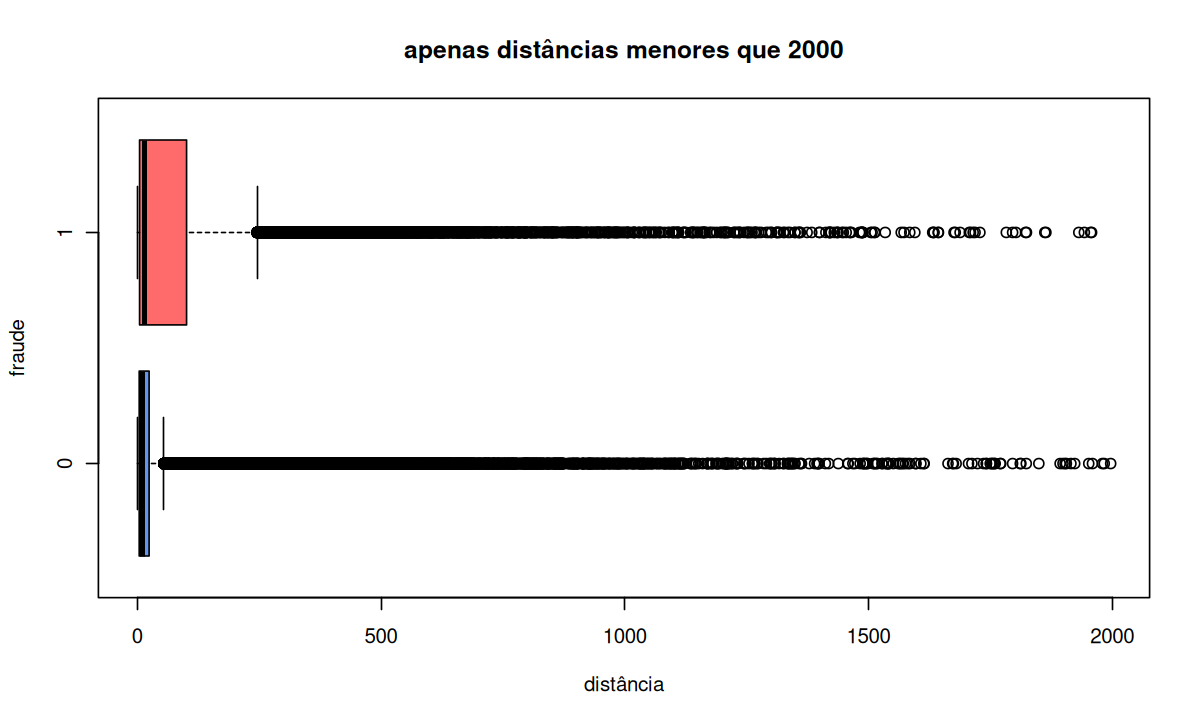

In [35]:
grafdim(10,6)
boxplot(frd$dist_orig[frd$dist_orig < 2000] ~ frd$fraude[frd$dist_orig < 2000],
        horizontal=TRUE,col=cor_classe, 
        main="apenas distâncias menores que 2000", xlab="distância",
        ylab="fraude")

In [36]:
print(cor(frd))

             dist_orig dist_ultima razao_compra   retorno      chip     senha
dist_orig     1.000000    0.000193    -0.001374  0.143124 -0.000697 -0.001622
dist_ultima   0.000193    1.000000     0.001013 -0.000928  0.002055 -0.000899
razao_compra -0.001374    0.001013     1.000000  0.001374  0.000587  0.000942
retorno       0.143124   -0.000928     0.001374  1.000000 -0.001345 -0.000417
chip         -0.000697    0.002055     0.000587 -0.001345  1.000000 -0.001393
senha        -0.001622   -0.000899     0.000942 -0.000417 -0.001393  1.000000
online       -0.001301    0.000141    -0.000330 -0.000532 -0.000219 -0.000291
fraude        0.187571    0.091917     0.462305 -0.001357 -0.060975 -0.100293
                online   fraude
dist_orig    -0.001301  0.18757
dist_ultima   0.000141  0.09192
razao_compra -0.000330  0.46230
retorno      -0.000532 -0.00136
chip         -0.000219 -0.06097
senha        -0.000291 -0.10029
online        1.000000  0.19197
fraude        0.191973  1.00000


### Vamos separar os dados de teste e validação dos dados de treinamento

A questão é que devemos obter (e retirar) dos dados originais cada grupo (teste, validação) deixando apenas os dados de treinamento.

In [37]:
# reajustando a semente aleatória
set.seed(997)

Vamos examinar a proporção de positivos na população:

In [38]:
cat("Proporção de positivos: ", round(sum(frd$fraude) / nrow(frd) * 100, 4), "%")

Proporção de positivos:  8.74 %

A população de casos positivos é apenas 8,7% da população total. A saída para balancear um pouco a proporção seria subamostrar os negativos.

In [39]:
neg   <- frd[frd$fraude == 0, ]
(nneg <- nrow(neg))
pos   <- frd[frd$fraude == 1, ]
(npos <- nrow(pos))

[1] 912597

[1] 87403

In [40]:
amostra <- sample(1:nneg, (2 * npos), replace=FALSE)
# criando uma base com uma amostragem de 2*npos de negativos
base    <- neg[amostra,]
nrow(base)
# criando um data frame com a amostragem dos negativos e todos
# positivos
frp <- rbind(base,pos)
nrow(frp)

[1] 174806

[1] 262209

In [41]:
cat("Proporção de positivos: ", round(sum(frp$fraude) / nrow(frp) * 100, 4), "%")

Proporção de positivos:  33.3 %

Feita a subamostragem dos negativos, vamos separar os conjuntos em _treino_, _validação_ e _teste_.

In [42]:
# reservando 20% dos dados originais para teste
taxa_teste  <- 0.2              
# reservando a mesma quantidade de teste para validação
taxa_valid  <- taxa_teste       
# o que sobrar é para o treinamento:
taxa_treino <- 1.0 - taxa_teste - taxa_valid

In [43]:
(n_teste  <- trunc(taxa_teste * nrow(frp)))
(n_valid  <- trunc(taxa_valid * nrow(frp)))

[1] 52441

[1] 52441

In [44]:
# como vamos _retirar_ validação e teste, o que _sobrar_ é o treino
# então, inicialmente, o treino é todo mundo.
treino  <- frp                 

In [45]:
# amostrando n_teste valores dentre 1 até quantidade de 
# linhas de treino para o conjunto de TESTE
amostra <- sample(1:nrow(treino), n_teste, replace=FALSE)
teste   <- treino[amostra,]   # "teste" recebe as linhas amostradas
treino  <- treino[-amostra,]  # retirando de "treino" os elementos do teste

In [46]:
# amostrando n_valid valores dentre 1 até quantidade de 
# linhas (restantes) de treino para o conjunto de VALIDAÇÃO
amostra <- sample(1:nrow(treino), n_valid, replace=FALSE)
valid   <- treino[amostra,]
treino  <- treino[-amostra,]     # retirando de "treino" os elementos da validação

In [47]:
nrow(teste)
nrow(valid)
nrow(treino)

[1] 52441

[1] 52441

[1] 157327

Vamos então checar os conjuntos de dados:

In [48]:
print(merge(treino, valid,  all=FALSE))

[1] dist_orig    dist_ultima  razao_compra retorno      chip        
[6] senha        online       fraude      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e validação.

In [49]:
print(merge(treino, teste,  all=FALSE))

[1] dist_orig    dist_ultima  razao_compra retorno      chip        
[6] senha        online       fraude      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e teste.

In [50]:
print(merge(valid, teste,  all=FALSE))

[1] dist_orig    dist_ultima  razao_compra retorno      chip        
[6] senha        online       fraude      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e teste, podemos começar o aprendizado.

### Avaliação dos dados

In [51]:
summary(treino)

   dist_orig         dist_ultima        razao_compra         retorno     
 Min.   :2.40e-02   Min.   :4.00e-04   Min.   :7.43e-03   Min.   :0.000  
 1st Qu.:4.04e+00   1st Qu.:3.06e-01   1st Qu.:5.78e-01   1st Qu.:1.000  
 Median :1.10e+01   Median :1.05e+00   Median :1.39e+00   Median :1.000  
 Mean   :3.72e+01   Mean   :7.10e+00   Mean   :2.95e+00   Mean   :0.881  
 3rd Qu.:3.16e+01   3rd Qu.:3.66e+00   3rd Qu.:4.24e+00   3rd Qu.:1.000  
 Max.   :1.06e+04   Max.   :2.12e+03   Max.   :2.67e+02   Max.   :1.000  
      chip           senha            online          fraude     
 Min.   :0.000   Min.   :0.0000   Min.   :0.000   Min.   :0.000  
 1st Qu.:0.000   1st Qu.:0.0000   1st Qu.:0.000   1st Qu.:0.000  
 Median :0.000   Median :0.0000   Median :1.000   Median :0.000  
 Mean   :0.326   Mean   :0.0746   Mean   :0.728   Mean   :0.332  
 3rd Qu.:1.000   3rd Qu.:0.0000   3rd Qu.:1.000   3rd Qu.:1.000  
 Max.   :1.000   Max.   :1.0000   Max.   :1.000   Max.   :1.000  

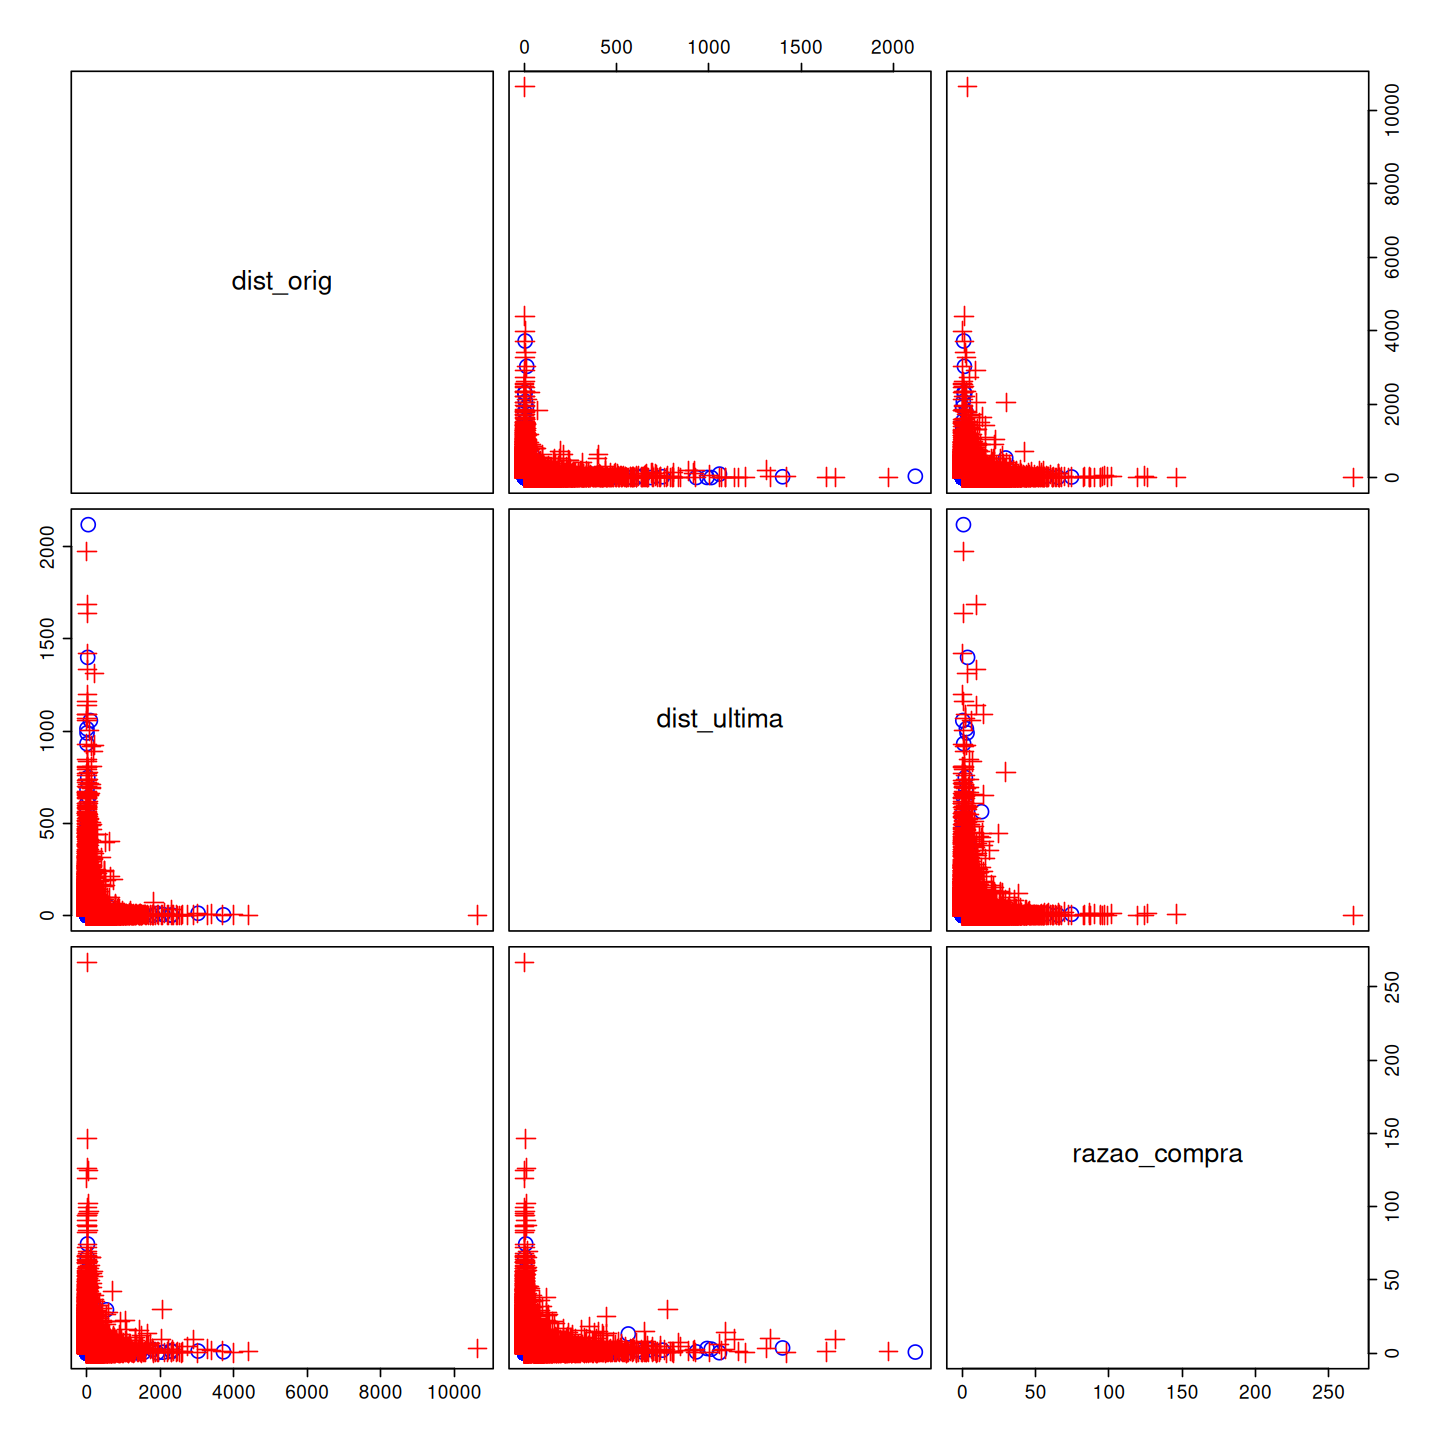

In [52]:
grafdim(12,12)
cor <- ifelse(treino$fraude == 1, "Red", "Blue")
tip <- ifelse(treino$fraude == 1, 3, 1) # fraude é "+", ok é "o"
plot(treino[,c("dist_orig", "dist_ultima","razao_compra")], 
     col=cor, pch=tip, cex=2.2, cex.lab=2.1, cex.axis=1.4)

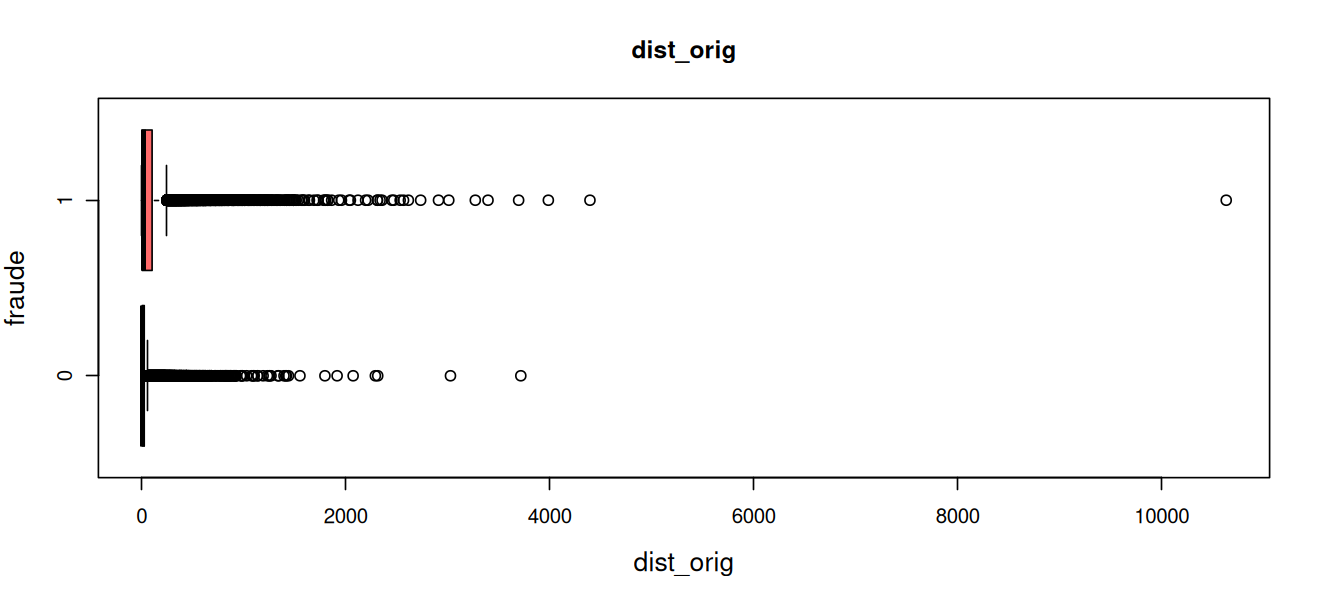

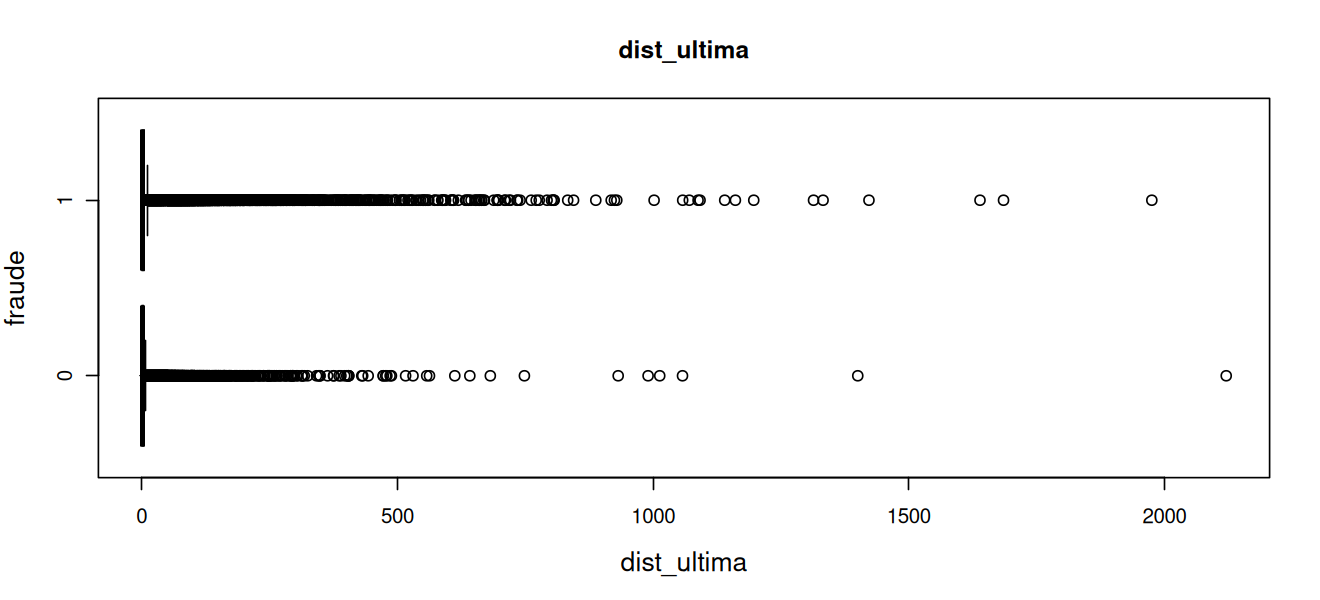

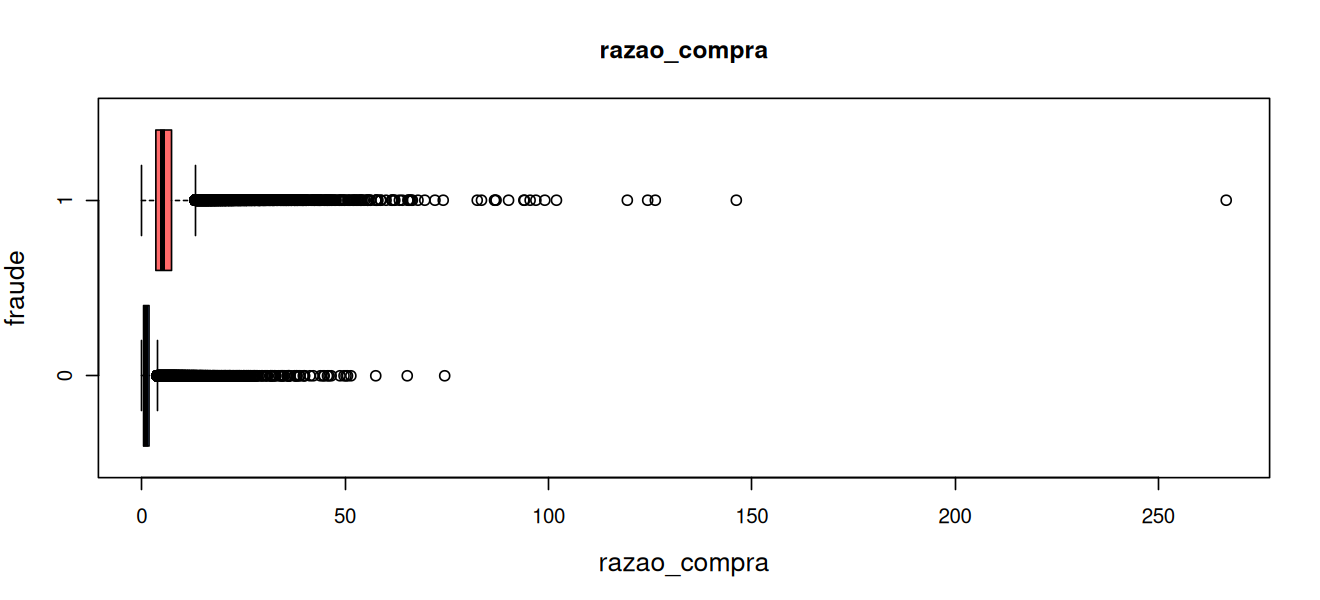

In [53]:
grafdim(11,5)
for (i in 1:3) {
    boxplot(treino[,i] ~ treino$fraude, main=names(treino)[i], 
            horizontal=TRUE, col=cor_classe, cex.lab=1.3, 
            xlab=names(treino)[i], ylab="fraude")
}

In [136]:
"Valores absolutos:______"
xtabs(~ retorno + fraude, data=treino)
""
"Proporção:_________________________"
ftable(proportions(xtabs(~ retorno + fraude, data=treino)))

[1] "Valores absolutos:______"

       fraude
retorno     0     1
      0 12378  6291
      1 92690 45968

[1] ""

[1] "Proporção:_________________________"

        fraude      0      1
retorno                     
0              0.0787 0.0400
1              0.5892 0.2922

In [137]:
"Valores absolutos:______"
xtabs(~ chip + fraude, data=treino)
""
"Proporção:_________________________"
ftable(proportions(xtabs(~ chip + fraude, data=treino)))

[1] "Valores absolutos:______"

    fraude
chip     0     1
   0 67111 38871
   1 37957 13388

[1] ""

[1] "Proporção:_________________________"

     fraude      0      1
chip                     
0           0.4266 0.2471
1           0.2413 0.0851

In [138]:
"Valores absolutos:______"
xtabs(~ senha + fraude, data=treino)
""
"Proporção:_________________________"
ftable(proportions(xtabs(~ senha + fraude, data=treino)))

[1] "Valores absolutos:______"

     fraude
senha     0     1
    0 93488 52095
    1 11580   164

[1] ""

[1] "Proporção:_________________________"

      fraude       0       1
senha                       
0            0.59423 0.33113
1            0.07360 0.00104

In [139]:
"Valores absolutos:______"
xtabs(~ online + fraude, data=treino)
""
"Proporção:_________________________"
ftable(proportions(xtabs(~ online + fraude, data=treino)))

[1] "Valores absolutos:______"

      fraude
online     0     1
     0 40034  2824
     1 65034 49435

[1] ""

[1] "Proporção:_________________________"

       fraude      0      1
online                     
0             0.2545 0.0179
1             0.4134 0.3142

In [58]:
# há 3 variáveis para normalização
nvariaveis <- 3

In [59]:
treino_min <- numeric(nvariaveis)  
for (i in 1:nvariaveis) {
    treino_min[i] <- min(treino[,i])
}

In [60]:
print(treino_min)

[1] 0.024144 0.000419 0.007427


In [61]:
treino_max <- numeric(nvariaveis)
for (i in 1:nvariaveis) {
    treino_max[i] <- max(treino[,i])
}

In [62]:
print(treino_max)

[1] 10633  2121   267


Uma vez que o modelo é construído com os valores de treino, é praxe fazer a padronização dos dados de _validação_ e _teste_ com os valores do *__treinamento__*.

In [63]:
for (i in 1:nvariaveis) {
    amplitude <- treino_max[i] - treino_min[i]
    treino[,i] <- (treino[,i] - treino_min[i]) / amplitude
    valid[,i]  <- (valid[,i]  - treino_min[i]) / amplitude
    teste[,i]  <- (teste[,i]  - treino_min[i]) / amplitude
}

Pode acontecer, portanto, de aparecerem valores negativos e maiores que 1 na padronização MinMax, pois os máximos e mínimos não estavam no grupo de treino. Sem problema. A padronização por ZNorm não apresenta esse característica, porém também deve ser feita utilizando a média e o desvio do conjunto de treinamento.

In [64]:
print(head(treino))

       dist_orig dist_ultima razao_compra retorno chip senha online fraude
825082  0.000375    2.34e-05      0.01493       1    0     1      0      0
937779  0.002892    5.94e-04      0.01048       1    1     0      1      0
639284  0.004370    2.09e-02      0.00233       1    0     0      0      0
155561  0.000308    1.35e-03      0.00246       1    0     0      1      0
943228  0.000398    5.22e-03      0.00399       1    1     0      1      0
427057  0.000148    3.67e-05      0.04244       0    1     0      0      0


In [65]:
summary(treino)

   dist_orig         dist_ultima        razao_compra        retorno     
 Min.   :0.000000   Min.   :0.000000   Min.   :0.00000   Min.   :0.000  
 1st Qu.:0.000378   1st Qu.:0.000144   1st Qu.:0.00214   1st Qu.:1.000  
 Median :0.001030   Median :0.000493   Median :0.00517   Median :1.000  
 Mean   :0.003500   Mean   :0.003350   Mean   :0.01103   Mean   :0.881  
 3rd Qu.:0.002973   3rd Qu.:0.001726   3rd Qu.:0.01588   3rd Qu.:1.000  
 Max.   :1.000000   Max.   :1.000000   Max.   :1.00000   Max.   :1.000  
      chip           senha            online          fraude     
 Min.   :0.000   Min.   :0.0000   Min.   :0.000   Min.   :0.000  
 1st Qu.:0.000   1st Qu.:0.0000   1st Qu.:0.000   1st Qu.:0.000  
 Median :0.000   Median :0.0000   Median :1.000   Median :0.000  
 Mean   :0.326   Mean   :0.0746   Mean   :0.728   Mean   :0.332  
 3rd Qu.:1.000   3rd Qu.:0.0000   3rd Qu.:1.000   3rd Qu.:1.000  
 Max.   :1.000   Max.   :1.0000   Max.   :1.000   Max.   :1.000  

In [66]:
print(head(valid))

       dist_orig dist_ultima razao_compra retorno chip senha online fraude
608017  0.001147    0.113410      0.00235       1    0     0      1      1
793662  0.000626    0.000607      0.00342       1    0     0      1      0
780918  0.002760    0.005610      0.00529       1    1     0      1      0
845792  0.007123    0.000562      0.01993       1    0     1      0      0
589503  0.000987    0.001646      0.01982       1    0     0      1      1
618196  0.007459    0.000948      0.01650       1    0     0      1      1


In [67]:
summary(valid)

   dist_orig         dist_ultima        razao_compra          retorno     
 Min.   :2.00e-07   Min.   :0.000000   Min.   :-6.00e-07   Min.   :0.000  
 1st Qu.:3.76e-04   1st Qu.:0.000143   1st Qu.: 2.14e-03   1st Qu.:1.000  
 Median :1.03e-03   Median :0.000487   Median : 5.21e-03   Median :1.000  
 Mean   :3.55e-03   Mean   :0.003314   Mean   : 1.11e-02   Mean   :0.884  
 3rd Qu.:3.01e-03   3rd Qu.:0.001712   3rd Qu.: 1.60e-02   3rd Qu.:1.000  
 Max.   :3.74e-01   Max.   :0.758231   Max.   : 4.75e-01   Max.   :1.000  
      chip           senha            online          fraude     
 Min.   :0.000   Min.   :0.0000   Min.   :0.000   Min.   :0.000  
 1st Qu.:0.000   1st Qu.:0.0000   1st Qu.:0.000   1st Qu.:0.000  
 Median :0.000   Median :0.0000   Median :1.000   Median :0.000  
 Mean   :0.327   Mean   :0.0756   Mean   :0.731   Mean   :0.335  
 3rd Qu.:1.000   3rd Qu.:0.0000   3rd Qu.:1.000   3rd Qu.:1.000  
 Max.   :1.000   Max.   :1.0000   Max.   :1.000   Max.   :1.000  

## Modelo Padrão-Base (_Baseline_ )

Vamos construir um _padrão-base_ (`baseline`) para termos um critério para saber como os modelos estão se comportando.

In [68]:
mod_base <- glm(formula = fraude ~ . , data=treino, family="binomial")  

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


In [69]:
summary(mod_base)


Call:
glm(formula = fraude ~ ., family = "binomial", data = treino)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)   -8.1637     0.0619  -132.0   <2e-16 ***
dist_orig    264.6169     2.2805   116.0   <2e-16 ***
dist_ultima   90.6545     1.2004    75.5   <2e-16 ***
razao_compra 288.7800     1.7149   168.4   <2e-16 ***
retorno       -1.1733     0.0318   -36.9   <2e-16 ***
chip          -1.1287     0.0233   -48.4   <2e-16 ***
senha        -10.8344     0.1918   -56.5   <2e-16 ***
online         5.2694     0.0493   106.8   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 200027  on 157326  degrees of freedom
Residual deviance:  67032  on 157319  degrees of freedom
AIC: 67048

Number of Fisher Scoring iterations: 9


Calculando quanto foi o erro absoluto médio entre os valores preditos pelo modelo `baseline` e o que, de fato, foi obtido (variável dependete `preco`) para os dados de **_treinamento_**.

In [70]:
mod_base_pred <- ifelse(predict(mod_base, type="response") > 0.5, 1, 0)

In [72]:
library(caret)
mod_base_matconf <- confusionMatrix(
                        data=as.factor(mod_base_pred), 
                        reference=as.factor(treino$fraude),
                        positive="1")

In [73]:
print(mod_base_matconf)

Confusion Matrix and Statistics

          Reference
Prediction      0      1
         0 100706   5738
         1   4362  46521
                                        
               Accuracy : 0.936         
                 95% CI : (0.935, 0.937)
    No Information Rate : 0.668         
    P-Value [Acc > NIR] : <2e-16        
                                        
                  Kappa : 0.854         
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.890         
            Specificity : 0.958         
         Pos Pred Value : 0.914         
         Neg Pred Value : 0.946         
             Prevalence : 0.332         
         Detection Rate : 0.296         
   Detection Prevalence : 0.323         
      Balanced Accuracy : 0.924         
                                        
       'Positive' Class : 1             
                                        


In [74]:
(mod_base_treino_accbal <- mod_base_matconf$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.924

In [75]:
mod_base_pred <- ifelse(predict(mod_base, type="response", newdata=valid) > 0.5, 1, 0)

In [76]:
mod_base_matconf <- confusionMatrix(
                        data=as.factor(mod_base_pred), 
                        reference=as.factor(valid$fraude),
                        positive="1")
print(mod_base_matconf)
(mod_base_valid_accbal <- mod_base_matconf$byClass["Balanced Accuracy"])

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 33460  1883
         1  1437 15661
                                        
               Accuracy : 0.937         
                 95% CI : (0.935, 0.939)
    No Information Rate : 0.665         
    P-Value [Acc > NIR] : < 2e-16       
                                        
                  Kappa : 0.857         
                                        
 Mcnemar's Test P-Value : 1.14e-14      
                                        
            Sensitivity : 0.893         
            Specificity : 0.959         
         Pos Pred Value : 0.916         
         Neg Pred Value : 0.947         
             Prevalence : 0.335         
         Detection Rate : 0.299         
   Detection Prevalence : 0.326         
      Balanced Accuracy : 0.926         
                                        
       'Positive' Class : 1             
                                        


Balanced Accuracy 
            0.926

Vamos montar então um conjunto de modelos 

In [77]:
str(treino)

'data.frame':	157327 obs. of  8 variables:
 $ dist_orig   : num  0.000375 0.002892 0.00437 0.000308 0.000398 ...
 $ dist_ultima : num  2.34e-05 5.94e-04 2.09e-02 1.35e-03 5.22e-03 ...
 $ razao_compra: num  0.01493 0.01048 0.00233 0.00246 0.00399 ...
 $ retorno     : num  1 1 1 1 1 0 1 1 0 1 ...
 $ chip        : num  0 1 0 0 1 1 0 0 0 0 ...
 $ senha       : num  1 0 0 0 0 0 0 1 0 0 ...
 $ online      : num  0 1 0 1 1 0 0 1 1 0 ...
 $ fraude      : num  0 0 0 0 0 0 0 0 0 0 ...


In [78]:
formula_potencia <- function (var_dep, base, variaveis, ate_potencia=5) {
    frm <- character(ate_potencia)
    b <- ""
    if (length(base) != 1 | trimws(base[1]) != "") {
        for (i in 1:length(base))
            b <- paste(b,base[i],"+",sep=" ")
    }
    base <- b
    for (i in 1:ate_potencia) {
        mais <- ""
        f <- ""
        for (j in 1:length(variaveis)) {
            if (i == 1) {
                f <- paste(f, mais," ", variaveis[j], sep="")
            }
            else {
               f <- paste(f, mais, " I(",variaveis[j],"^",i,")", sep="")
            }
            mais <- " +"
        }
        if (i == 1) {
            frm[i] <- paste(base, f)
        }
        else {
            frm[i] <- paste(frm[i-1], " +", f, sep="")
        }
    }
    for (i in 1:ate_potencia) 
        frm[i]    <- paste(var_dep, " ~", frm[i], sep="")
    return (frm)
}

Criando um conjunto de fórmulas, uma para cada potência, para serem utilizadas uma em cada regressão.

In [79]:
# variáveis que não vão ser elevadas à potência, como as categóricas
# temos categóricas, mas não vamos usá-las neste momento
base <- c("retorno", "chip", "senha", "online") 

# variáveis a serem utilizadas como potência no modelo
vars    <- c("dist_orig", "dist_ultima", "razao_compra")

# variável dependente
var_dependente <- "fraude"

In [80]:
formulas <- formula_potencia(var_dependente, base, vars, ate_potencia=9)

In [81]:
formulas[1]

[1] "fraude ~ retorno + chip + senha + online +  dist_orig + dist_ultima + razao_compra"

In [82]:
formulas[3]

[1] "fraude ~ retorno + chip + senha + online +  dist_orig + dist_ultima + razao_compra + I(dist_orig^2) + I(dist_ultima^2) + I(razao_compra^2) + I(dist_orig^3) + I(dist_ultima^3) + I(razao_compra^3)"

In [83]:
# criando um vetor numérico vazio (com 0.0) pra guardar os 
# erros médios absolutos de cada fórmula
treino_acc <- numeric(length(formulas))
valid_acc  <- numeric(length(formulas))

In [84]:
for (i in 1:length(formulas)) {
    modelo <- glm(formula=formula(formulas[i]), data=treino, family="binomial")
    
    predito <- ifelse(predict(modelo, type="response") > 0.5, 1, 0)
    matconf <- confusionMatrix(data=as.factor(predito), 
                               reference=as.factor(treino$fraude), positive="1")
    treino_acc[i] <- matconf$byClass["Balanced Accuracy"]
    
    predito <- ifelse(predict(modelo, type="response", newdata=valid) > 0.5, 1, 0)
    matconf <- confusionMatrix(data=as.factor(predito), 
                               reference=as.factor(valid$fraude), positive="1")
    valid_acc[i] <- matconf$byClass["Balanced Accuracy"]
    print(paste(i," acurácia balanceada treino:",treino_acc[i],
                "   validação:",valid_acc[i]))
}

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "1  acurácia balanceada treino: 0.924342380182529    validação: 0.925745766928383"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "2  acurácia balanceada treino: 0.924387061066201    validação: 0.926432234371279"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "3  acurácia balanceada treino: 0.817135025029989    validação: 0.81752460364075"


... (8 outputs left out)

Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "8  acurácia balanceada treino: 0.901461972996261    validação: 0.899935957058752"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "9  acurácia balanceada treino: 0.917538313626222    validação: 0.916549608285714"


Acurácia balanceada dos dados de treinamento:

In [85]:
print(treino_acc)

[1] 0.924 0.924 0.817 0.931 0.871 0.929 0.904 0.901 0.918


Acurácia balanceada para dados de validação:

In [86]:
print(valid_acc)

[1] 0.926 0.926 0.818 0.932 0.870 0.930 0.904 0.900 0.917


In [87]:
names(treino)

[1] "dist_orig"    "dist_ultima"  "razao_compra" "retorno"      "chip"        
[6] "senha"        "online"       "fraude"

In [88]:
# ajustando os limites do eixo y do gráfico:
# yl  <- c(min(c(treino_acc, valid_acc, mod_base_valid_accbal)),
#          max(c(treino_acc, valid_acc, mod_base_valid_accbal)))
yl <- c(0.81, 0.95)
tam <- 1.2
cor_treino <- "blue"
cor_valid  <- "forestgreen"
ponto_treino <- 2
ponto_valid  <- 0
tipo_linha <- 1
larg_linha <- 1

In [89]:
grafdim(12,9)

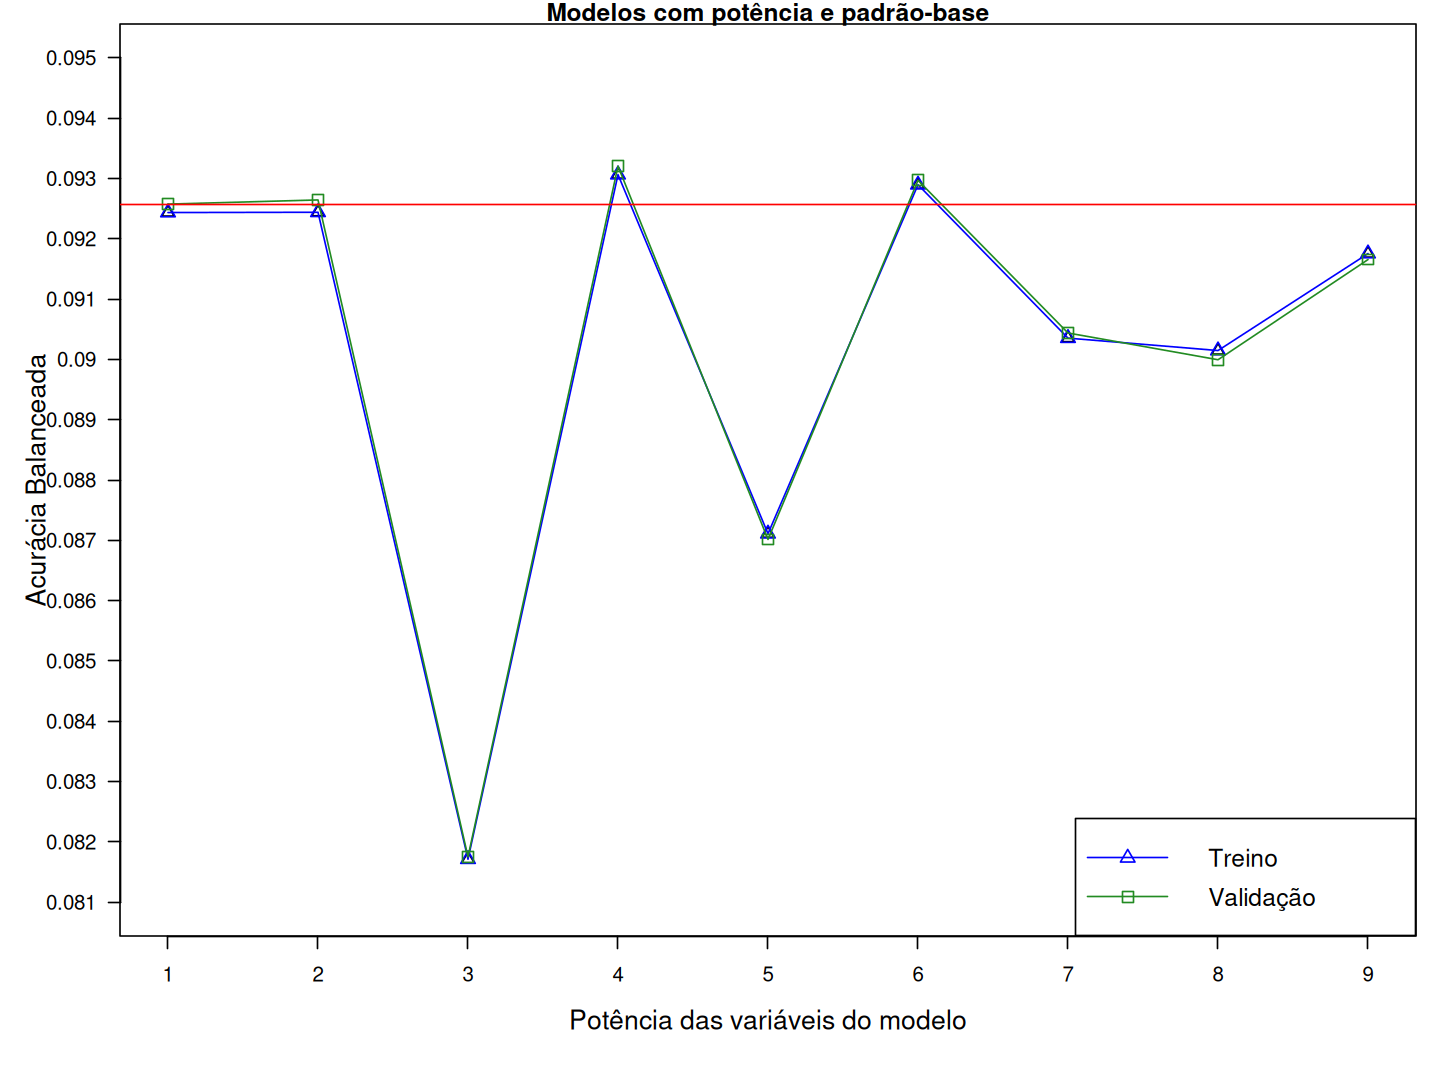

In [92]:
# deixando margem mais larga à esquerda no gráfico. 
# margem é c(baixo, esquerda, topo, direita)
par(mar=c(6,5,1,1))

plot(treino_acc, 
     xlab="Potência das variáveis do modelo", 
     ylab="Acurácia Balanceada", 
     ylim=yl, xaxt="n", pch=ponto_treino, yaxt="n", cex.lab=1.3,
     main="Modelos com potência e padrão-base")

points(treino_acc, cex=tam , pch=ponto_treino, col=cor_treino)
lines(treino_acc, lty=tipo_linha, lwd=larg_linha, col=cor_treino)

points(valid_acc, cex=tam , pch=ponto_valid, col=cor_valid)
lines(valid_acc, lty=tipo_linha, lwd=larg_linha, col=cor_valid)

axis(1, at=1:length(treino_acc), las=1)

eixoy <- seq(yl[1],yl[2],length=15)
axis(2, at=eixoy, labels=round(eixoy/10,3), las=1)

abline(h=mod_base_valid_accbal, lwd=larg_linha, col="red")

legend(x="bottomright", legend=c("Treino","Validação"), 
       col=c(cor_treino,cor_valid),
       lty=tipo_linha, lwd=larg_linha, 
       pch=c(ponto_treino,ponto_valid), cex=1.2)

# voltando as margens para o padrão
par(mar=c(3,3,3,3))

### Análise

O gráfico mostra que a acurácia balanceada dos modelos flutuou conforme a potência das variáveis numéricas aumentou. O modelo que apresentou a melhor acurácia foi o de ordem 4, ou seja:

In [93]:
formulas[4]

[1] "fraude ~ retorno + chip + senha + online +  dist_orig + dist_ultima + razao_compra + I(dist_orig^2) + I(dist_ultima^2) + I(razao_compra^2) + I(dist_orig^3) + I(dist_ultima^3) + I(razao_compra^3) + I(dist_orig^4) + I(dist_ultima^4) + I(razao_compra^4)"

## Modelo com interação entre variáveis

Talvez haja interação entre variáveis, como comportamento de `senha` se ocorreu `online` ou não.

In [94]:
# variáveis que não vão ser elevadas à potência, como as categóricas
# temos categóricas, mas não vamos usá-las neste momento
base <- c("retorno * chip * senha * online") 

# variáveis a serem utilizadas como potência no modelo
vars    <- c("dist_orig", "dist_ultima", "razao_compra")

# variável dependente
var_dependente <- "fraude"

In [95]:
formulas_n2 <- formula_potencia(var_dependente, base, vars, ate_potencia=9)

In [96]:
formulas_n2[1]

[1] "fraude ~ retorno * chip * senha * online +  dist_orig + dist_ultima + razao_compra"

In [97]:
formulas_n2[3]

[1] "fraude ~ retorno * chip * senha * online +  dist_orig + dist_ultima + razao_compra + I(dist_orig^2) + I(dist_ultima^2) + I(razao_compra^2) + I(dist_orig^3) + I(dist_ultima^3) + I(razao_compra^3)"

In [98]:
# criando um vetor numérico vazio (com 0.0) pra guardar os 
# erros médios absolutos de cada fórmula
treino_n2_acc <- numeric(length(formulas))
valid_n2_acc  <- numeric(length(formulas))

In [99]:
for (i in 1:length(formulas_n2)) {
    modelo <- glm(formula=formula(formulas_n2[i]), data=treino, family="binomial")
    
    predito <- ifelse(predict(modelo, type="response") > 0.5, 1, 0)
    matconf <- confusionMatrix(data=as.factor(predito), 
                               reference=as.factor(treino$fraude), positive="1")
    treino_n2_acc[i] <- matconf$byClass["Balanced Accuracy"]
    
    predito <- ifelse(predict(modelo, type="response", newdata=valid) > 0.5, 1, 0)
    matconf <- confusionMatrix(data=as.factor(predito), 
                               reference=as.factor(valid$fraude), positive="1")
    valid_n2_acc[i] <- matconf$byClass["Balanced Accuracy"]
    print(paste(i," acurácia balanceada treino:",treino_n2_acc[i],
                "   validação:",valid_n2_acc[i]))
}

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "1  acurácia balanceada treino: 0.940117765493504    validação: 0.942887856702287"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "2  acurácia balanceada treino: 0.943744187208839    validação: 0.94518934171477"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "3  acurácia balanceada treino: 0.807717354024803    validação: 0.808514593091955"


... (8 outputs left out)

Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "8  acurácia balanceada treino: 0.919546888281397    validação: 0.917077422887165"


Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


[1] "9  acurácia balanceada treino: 0.945958744341071    validação: 0.946920854154329"


Acurácia balanceada dos dados de treinamento:

In [100]:
print(treino_n2_acc)

[1] 0.940 0.944 0.808 0.945 0.944 0.933 0.920 0.920 0.946


Acurácia balanceada para dados de validação:

In [101]:
print(valid_n2_acc)

[1] 0.943 0.945 0.809 0.947 0.946 0.935 0.922 0.917 0.947


### Análise

In [102]:
# ajustando os limites do eixo y do gráfico:
yl <- c(0.81, 0.95)
tam <- 1.8
cor_treino <- "blue"
cor_valid  <- "forestgreen"
cor_teste  <- "red"
cor_baseline <- "tomato4"
ponto_treino <- 2
ponto_valid  <- 0
ponto_teste  <- 10
tipo_linha <- 1
tipo_linha_n2 <- 2
larg_linha <- 1.3

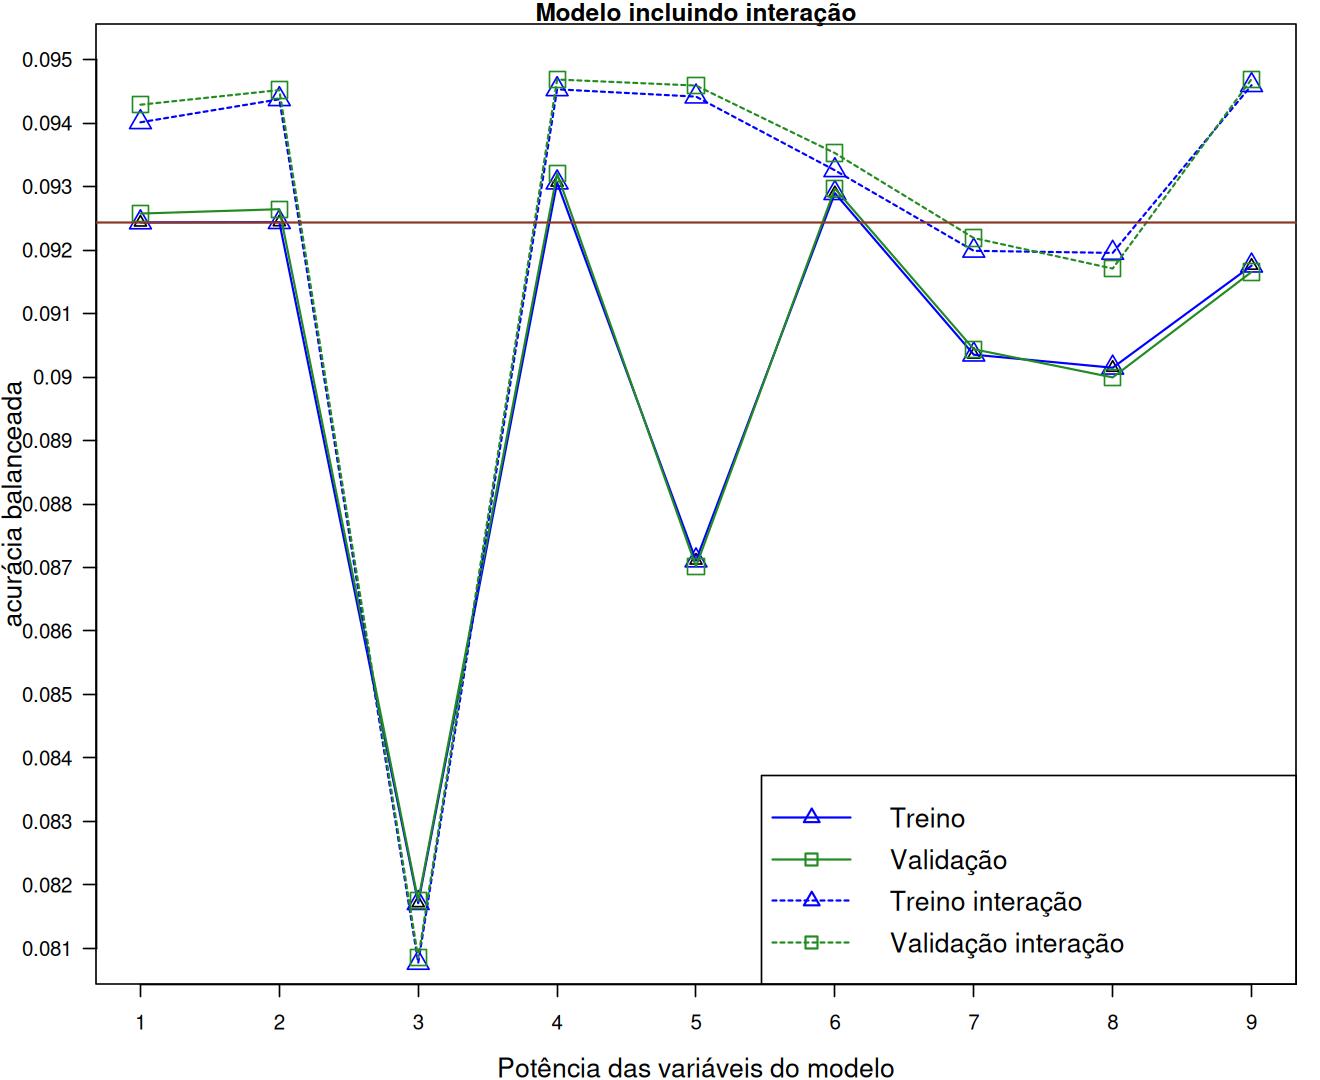

In [103]:
grafdim(11,9)
# deixando margem mais larga à esquerda no gráfico. 
# margem é c(baixo, esquerda, topo, direita)
par(mar=c(4,4,1,1))

plot(treino_acc, 
     xlab="Potência das variáveis do modelo", 
     ylab="acurácia balanceada", 
     ylim=yl, xaxt="n", pch=ponto_treino, cex.lab=1.3, cex.main=1.2,
     yaxt="n", main="Modelo incluindo interação")

points(treino_acc, cex=tam , pch=ponto_treino, col=cor_treino)
lines(treino_acc, lty=tipo_linha, lwd=larg_linha, col=cor_treino)

points(valid_acc, cex=tam , pch=ponto_valid, col=cor_valid)
lines(valid_acc, lty=tipo_linha, lwd=larg_linha, col=cor_valid)

points(treino_n2_acc, cex=tam , pch=ponto_treino, col=cor_treino)
lines(treino_n2_acc, lty=tipo_linha_n2, lwd=larg_linha, col=cor_treino)

points(valid_n2_acc, cex=tam , pch=ponto_valid, col=cor_valid)
lines(valid_n2_acc, lty=tipo_linha_n2, lwd=larg_linha, col=cor_valid)

axis(1, at=1:length(treino_acc), las=1)

eixoy <- seq(yl[1],yl[2],length=15)
axis(2, at=eixoy, labels=round(eixoy/10,3), las=1)

abline(h=mod_base_treino_accbal, lwd=larg_linha, col=cor_baseline)

legend(x="bottomright", 
       legend=c("Treino","Validação","Treino interação","Validação interação"), 
       col=c(cor_treino,cor_valid,cor_treino,cor_valid),
       lty=c(tipo_linha,tipo_linha,tipo_linha_n2,tipo_linha_n2),lwd=larg_linha, 
       pch=c(ponto_treino,ponto_valid,ponto_treino,ponto_valid), cex=1.3)

# voltando as margens para o padrão
par(mar=c(3,3,3,3))

## Melhor modelo

O modelo com variáveis (_features_) com 4ª potência e interação entre variáveis OHE. Por questão de simplicidade, o modelo com interação e potência de 2º grau também seria uma opção.

In [104]:
(formula_melhor_modelo <- formulas_n2[4])

[1] "fraude ~ retorno * chip * senha * online +  dist_orig + dist_ultima + razao_compra + I(dist_orig^2) + I(dist_ultima^2) + I(razao_compra^2) + I(dist_orig^3) + I(dist_ultima^3) + I(razao_compra^3) + I(dist_orig^4) + I(dist_ultima^4) + I(razao_compra^4)"

A avaliação final do modelo é feita verificando qual o seu desempenho com os dados de teste:

In [105]:
melhor_modelo <- glm(formula=formula(formula_melhor_modelo), data=treino, family="binomial")

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


In [106]:
summary(melhor_modelo)


Call:
glm(formula = formula(formula_melhor_modelo), family = "binomial", 
    data = treino)

Coefficients:
                           Estimate Std. Error z value Pr(>|z|)    
(Intercept)               -7.95e+00   9.38e-02  -84.78  < 2e-16 ***
retorno                   -9.72e+00   1.23e-01  -78.91  < 2e-16 ***
chip                      -1.05e+01   5.48e-01  -19.12  < 2e-16 ***
senha                     -1.96e+01   9.92e+01   -0.20     0.84    
online                     4.42e-01   9.22e-02    4.79  1.7e-06 ***
dist_orig                  6.32e+02   5.45e+00  115.97  < 2e-16 ***
dist_ultima                2.33e+02   2.79e+00   83.33  < 2e-16 ***
razao_compra               6.48e+02   4.94e+00  131.05  < 2e-16 ***
I(dist_orig^2)            -8.31e+03   1.18e+02  -70.50  < 2e-16 ***
I(dist_ultima^2)          -1.44e+03   3.99e+01  -36.08  < 2e-16 ***
I(razao_compra^2)         -7.75e+03   1.08e+02  -71.69  < 2e-16 ***
I(dist_orig^3)             3.16e+04   6.63e+02   47.70  < 2e-16 ***
I(dist_

In [107]:
predito_prob <- predict(melhor_modelo, type="response")
teste_pred <- ifelse(predict(melhor_modelo, type="response", newdata=teste) > 0.5, 1, 0)
matconf <- confusionMatrix(data=as.factor(teste_pred), 
                               reference=as.factor(teste$fraude), positive="1")
print(matconf)
(teste_acc <- matconf$byClass["Balanced Accuracy"])

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 33461  1234
         1  1380 16366
                                        
               Accuracy : 0.95          
                 95% CI : (0.948, 0.952)
    No Information Rate : 0.664         
    P-Value [Acc > NIR] : < 2e-16       
                                        
                  Kappa : 0.888         
                                        
 Mcnemar's Test P-Value : 0.00457       
                                        
            Sensitivity : 0.930         
            Specificity : 0.960         
         Pos Pred Value : 0.922         
         Neg Pred Value : 0.964         
             Prevalence : 0.336         
         Detection Rate : 0.312         
   Detection Prevalence : 0.338         
      Balanced Accuracy : 0.945         
                                        
       'Positive' Class : 1             
                                        


Balanced Accuracy 
            0.945

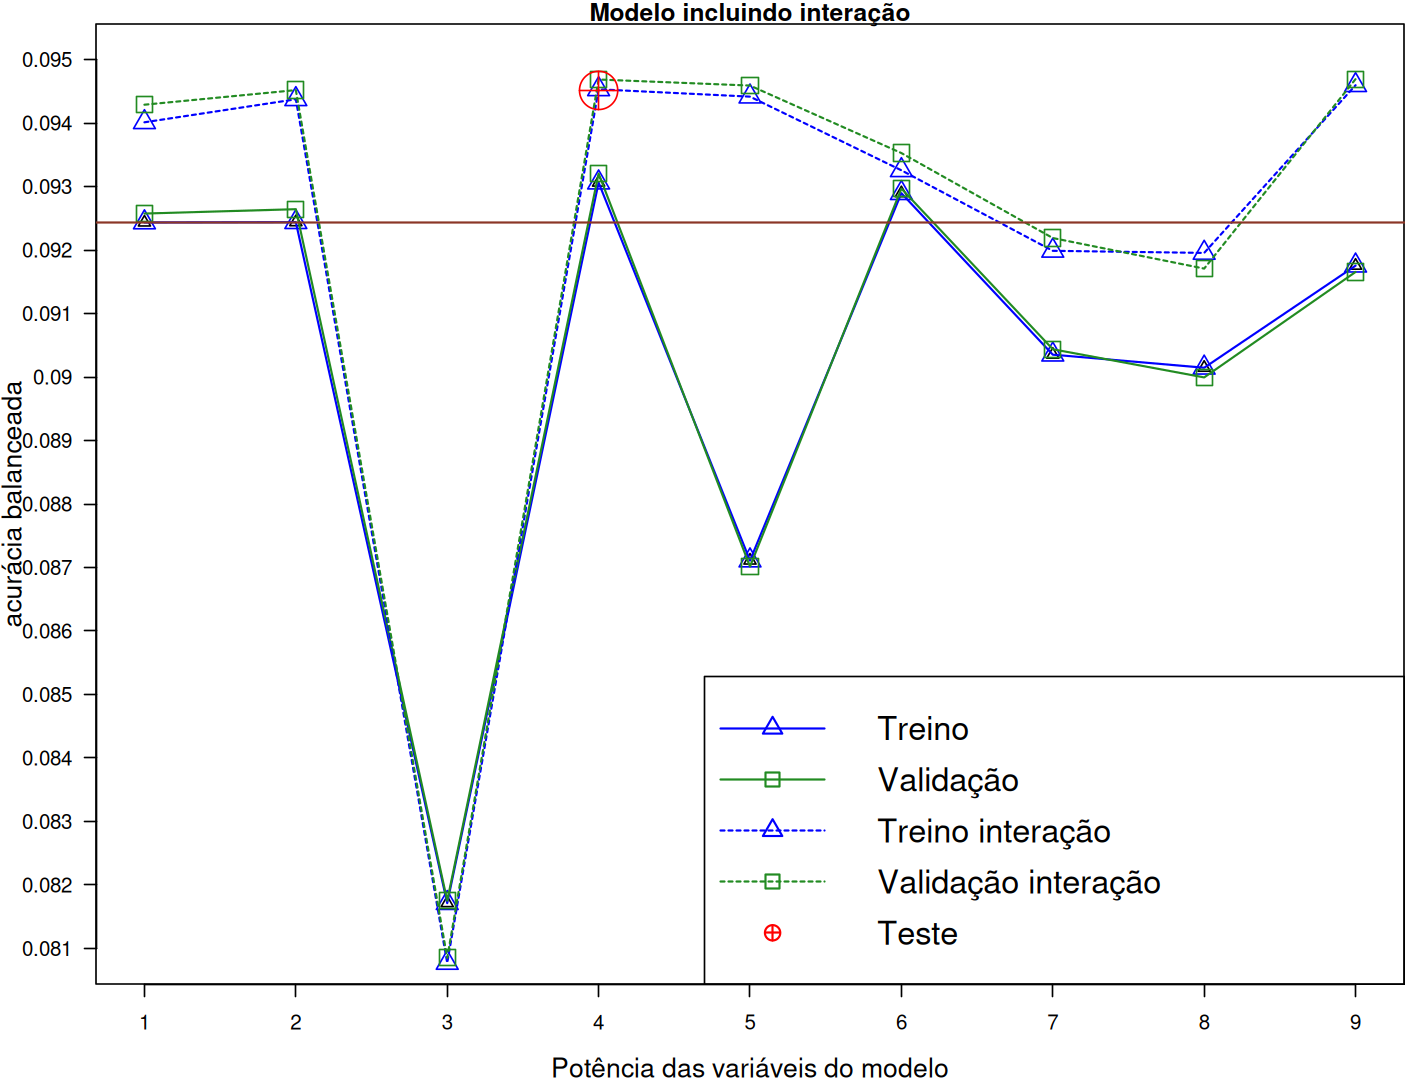

In [108]:
grafdim(11.9)
# deixando margem mais larga à esquerda no gráfico. 
# margem é c(baixo, esquerda, topo, direita)
par(mar=c(4,4,1,1))

plot(treino_acc,
     xlab="Potência das variáveis do modelo",
     ylab="acurácia balanceada",
     ylim=yl, xaxt="n", pch=ponto_treino, cex.lab=1.3,cex.main=1.2,
     yaxt="n", main="Modelo incluindo interação")

points(treino_acc, cex=tam , pch=ponto_treino, col=cor_treino)
lines(treino_acc, lty=tipo_linha, lwd=larg_linha, col=cor_treino)

points(valid_acc, cex=tam , pch=ponto_valid, col=cor_valid)
lines(valid_acc, lty=tipo_linha, lwd=larg_linha, col=cor_valid)

points(treino_n2_acc, cex=tam , pch=ponto_treino, col=cor_treino)
lines(treino_n2_acc, lty=tipo_linha_n2, lwd=larg_linha, col=cor_treino)

points(valid_n2_acc, cex=tam , pch=ponto_valid, col=cor_valid)
lines(valid_n2_acc, lty=tipo_linha_n2, lwd=larg_linha, col=cor_valid)

points(4, teste_acc, cex=2.3*tam, pch=ponto_teste, col=cor_teste)

axis(1, at=1:length(treino_acc), las=1)

eixoy <- seq(yl[1],yl[2],length=15)
axis(2, at=eixoy, labels=round(eixoy/10,3), las=1)

abline(h=mod_base_treino_accbal, lwd=larg_linha, col=cor_baseline)

legend(x="bottomright", cex=tam-0.2,
       legend=c("Treino","Validação","Treino interação",
                "Validação interação","Teste"), 
       col=c(cor_treino,cor_valid,cor_treino,cor_valid,cor_teste),
       lty=c(tipo_linha,tipo_linha,tipo_linha_n2,tipo_linha_n2,0), 
             lwd=larg_linha, pch=c(ponto_treino,ponto_valid, 
                                   ponto_treino,ponto_valid,ponto_teste))

# voltando as margens para o padrão
par(mar=c(3,3,3,3))

Pode-se observar que o modelo apresentou um desempenho marginalmente inferior que o esperado ao ser utilizado com os dados de teste, provavelmente  devido à variabilidade natural dos dados.

## Utilizando o modelo

Para utilizar o modelo, ou seja, prever um valor de preço mediano para um determinado distrito, basta ajustar os dados e pedir uma predição do modelo com os dados ajustados.

In [109]:
str(treino)
print(treino_min)

'data.frame':	157327 obs. of  8 variables:
 $ dist_orig   : num  0.000375 0.002892 0.00437 0.000308 0.000398 ...
 $ dist_ultima : num  2.34e-05 5.94e-04 2.09e-02 1.35e-03 5.22e-03 ...
 $ razao_compra: num  0.01493 0.01048 0.00233 0.00246 0.00399 ...
 $ retorno     : num  1 1 1 1 1 0 1 1 0 1 ...
 $ chip        : num  0 1 0 0 1 1 0 0 0 0 ...
 $ senha       : num  1 0 0 0 0 0 0 1 0 0 ...
 $ online      : num  0 1 0 1 1 0 0 1 1 0 ...
 $ fraude      : num  0 0 0 0 0 0 0 0 0 0 ...
[1] 0.024144 0.000419 0.007427


In [110]:
# Acrescentando valores para operar com todas variáveis, 
# sem interferir/alterar as variáveis categóricas one hot
padroniz_min <- c(treino_min,0,0,0,0,NA)
padroniz_max <- c(treino_max,1,1,1,1,NA)

Vamos considerar estimar se uma operação seria fraudulenta ou não:

In [111]:
caso <- treino[1,]              # pegando uma linha qualquer, só pela estrutura
row.names(caso)      <- 1       # só pra renumerar a linha de caso para 1
caso$dist_orig[1]    <- 10      # transação ocorreu 10 unidades de distância
caso$dist_ultima[1]  <- 0       # ocorreu no mesmo local da última transação
caso$razao_compra[1] <- 2       # duas vezes a mediana dos valores gastos
caso$retorno[1]      <- 1       # é um retorno
caso$chip[1]         <- 0       # não foi com chip
caso$senha[1]        <- 1       # mas foi com senha
caso$online[1]       <- 1       # foi online
caso$fraude[1]       <- NA      # é o que queremos saber

In [112]:
print(caso)

  dist_orig dist_ultima razao_compra retorno chip senha online fraude
1        10           0            2       1    0     1      1     NA


In [113]:
print(padroniz_min)
print(padroniz_max)

[1] 0.024144 0.000419 0.007427 0.000000 0.000000 0.000000 0.000000       NA
[1] 10633  2121   267     1     1     1     1    NA


É necessário padronizar:

In [114]:
caso <- (caso - padroniz_min) / (padroniz_max - padroniz_min)

In [115]:
print(caso)

  dist_orig dist_ultima razao_compra retorno chip senha online fraude
1  0.000938   -1.97e-07      0.00747       1    0     1      1     NA


In [116]:
(predicao_caso <- predict(melhor_modelo, type="response", newdata=caso))
(predicao_caso <- ifelse(predicao_caso > 0.5, 1, 0))
if (predicao_caso == 1) {    
    resposta <- "fraude"
} else {
    resposta <- "lícita"
}
print(paste("A previsão é que a transação seja",resposta))

1 
2.09e-06

1 
0

[1] "A previsão é que a transação seja lícita"


Outra situação:

In [117]:
caso$dist_orig[1]    <- 1000    # transação ocorreu 1000 unidades de distância
caso$dist_ultima[1]  <- 2000    # ocorreu à 2000 da última transação
caso$razao_compra[1] <- 5       # cinco vezes a mediana dos valores gastos
caso$retorno[1]      <- 0       # não é um retorno
caso$chip[1]         <- 0       # não foi com chip
caso$senha[1]        <- 1       # mas foi com senha
caso$online[1]       <- 1       # foi online
caso$fraude[1]       <- NA      # é o que queremos saber

In [118]:
caso <- (caso - padroniz_min) / (padroniz_max - padroniz_min)

In [119]:
caso

,dist_orig,dist_ultima,razao_compra,retorno,chip,senha,online,fraude
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.094,0.943,0.0187,0,0,1,1,NA


In [120]:
(predicao_caso <- predict(melhor_modelo, type="response", newdata=caso))
(predicao_caso <- ifelse(predicao_caso > 0.5, 1, 0))
if (predicao_caso == 1) {
    resposta <- "fraude"
} else {
    resposta <- "lícita"
}
print(paste("A previsão é que a transação seja",resposta))

1 
0.783

1 
1

[1] "A previsão é que a transação seja fraude"


## Curva ROC

In [121]:
library(ROCR)

In [122]:
predito_roc <- prediction(predito_prob, treino$fraude)

In [123]:
roc_perf <- performance(predito_roc, "tpr", "fpr")

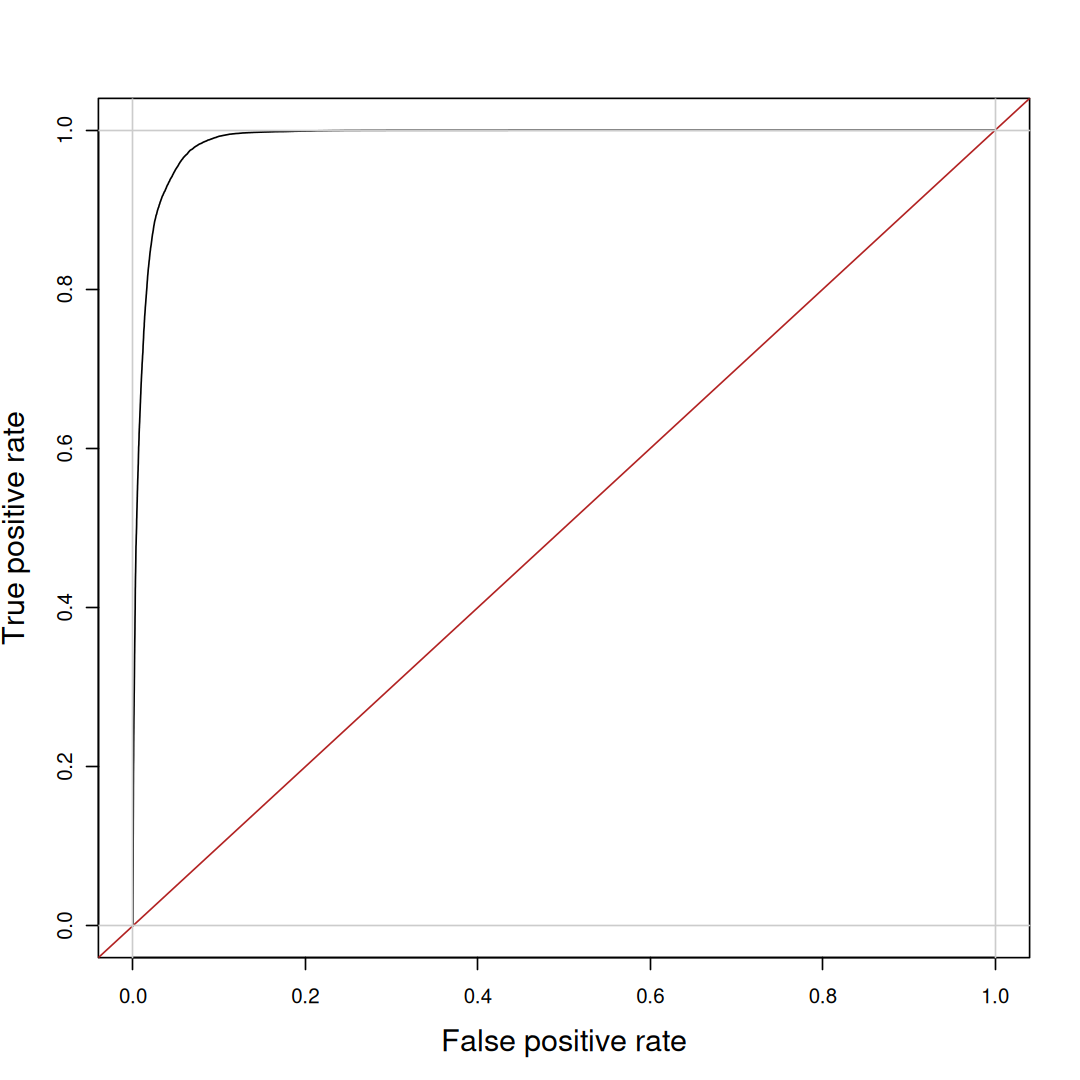

In [141]:
grafdim(9,9)
plot(roc_perf, cex.lab=1.5)
abline(a=0,b=1, col="firebrick")
abline(h=c(0,1), v=c(0,1), col="gray80")

In [142]:
auc_perf   <- performance(predito_roc, "auc")
auc_modelo <- auc_perf@y.values[[1]]
cat("Área sob a curva ROC:",auc_modelo)

Área sob a curva ROC: 0.989